In [7]:
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.gridspec as gridspec
from pathlib import Path

# ── Style settings ─────────────────────────────────────────────────────────────
plt.rcParams.update({
    'figure.facecolor':  '#F8F9FA',
    'axes.facecolor':    '#FFFFFF',
    'axes.grid':         True,
    'grid.alpha':        0.3,
    'axes.spines.top':   False,
    'axes.spines.right': False,
    'font.family':       'DejaVu Sans',
    'axes.titlesize':    11,
    'axes.labelsize':    9,
    'xtick.labelsize':   8,
    'ytick.labelsize':   8,
})

# Colour palette – consistent throughout dashboard
COL_CHURNED   = '#E74C3C'   # red  – churned customers
COL_RETAINED  = '#2ECC71'   # green – retained customers
COL_NEUTRAL   = '#3498DB'   # blue  – neutral / totals
ALPHA         = 0.80

# ── File path ──────────────────────────────────────────────────────────────────
DATA_DIR = Path('.')
PARQUET  = DATA_DIR / 'churn_dataset.parquet'

print(f'Matplotlib version: {matplotlib.__version__}')
print(f'Pandas version:     {pd.__version__}')

Matplotlib version: 3.11.2
Pandas version:     3.1.1


In [3]:
def load_dataset(path: Path) -> pd.DataFrame:
    """
    Load the churn Parquet dataset produced by the ETL pipeline.

    Parameters
    ----------
    path : Path
        Path to churn_dataset.parquet

    Returns
    -------
    pd.DataFrame
    """
    # Fallback to current working directory if the file is not in 'data/'
    resolved_path = path if path.exists() else Path(path.name)
    df = pd.read_parquet(resolved_path, engine='pyarrow')
    print(f'Loaded {len(df):,} customers  |  {df.shape[1]} columns')
    print(f'Churn rate: {df["churn"].mean():.1%}  ({df["churn"].sum()} churned)')
    return df

df = load_dataset(PARQUET)

# Convenience splits
churned  = df[df['churn'] == 1]
retained = df[df['churn'] == 0]

display(df.head())

Loaded 221 customers  |  31 columns
Churn rate: 38.9%  (86 churned)


,customer_id,email,subscription_id,subscription_type_name,subscription_type_id,subscription_days,auto_renew,churn,num_orders,total_spend_pence,...,uses_e_mail,uses_telephone,uses_live_chat,num_logins,days_since_last_login,num_unique_ips,device_type_mobile,device_type_tablet,device_type_desktop,login_frequency_per_day
0,1,Sargsyan701@somemail.co.uk,1,SuperSaver,3,30,0,1,20,74455,...,1,1,0,48,302,48,0,1,0,4.8000
1,2,Mammadova282@example.com,2,SuperSaver,3,330,1,0,253,1036961,...,1,1,1,1085,0,1085,0,1,0,3.4665
2,3,Sana858@notrealemail.com,3,Premium,1,330,1,0,304,1284692,...,1,1,1,624,0,624,0,1,0,1.9936
3,4,Omar.Farooq4@example.com,4,Premium,1,330,1,0,1055,9577504,...,1,1,1,1540,0,1540,0,1,0,4.9201
4,5,Alejandro357@somemail.co.uk,5,SuperSaver,3,120,0,1,44,179738,...,1,1,1,388,210,388,1,0,0,3.7670


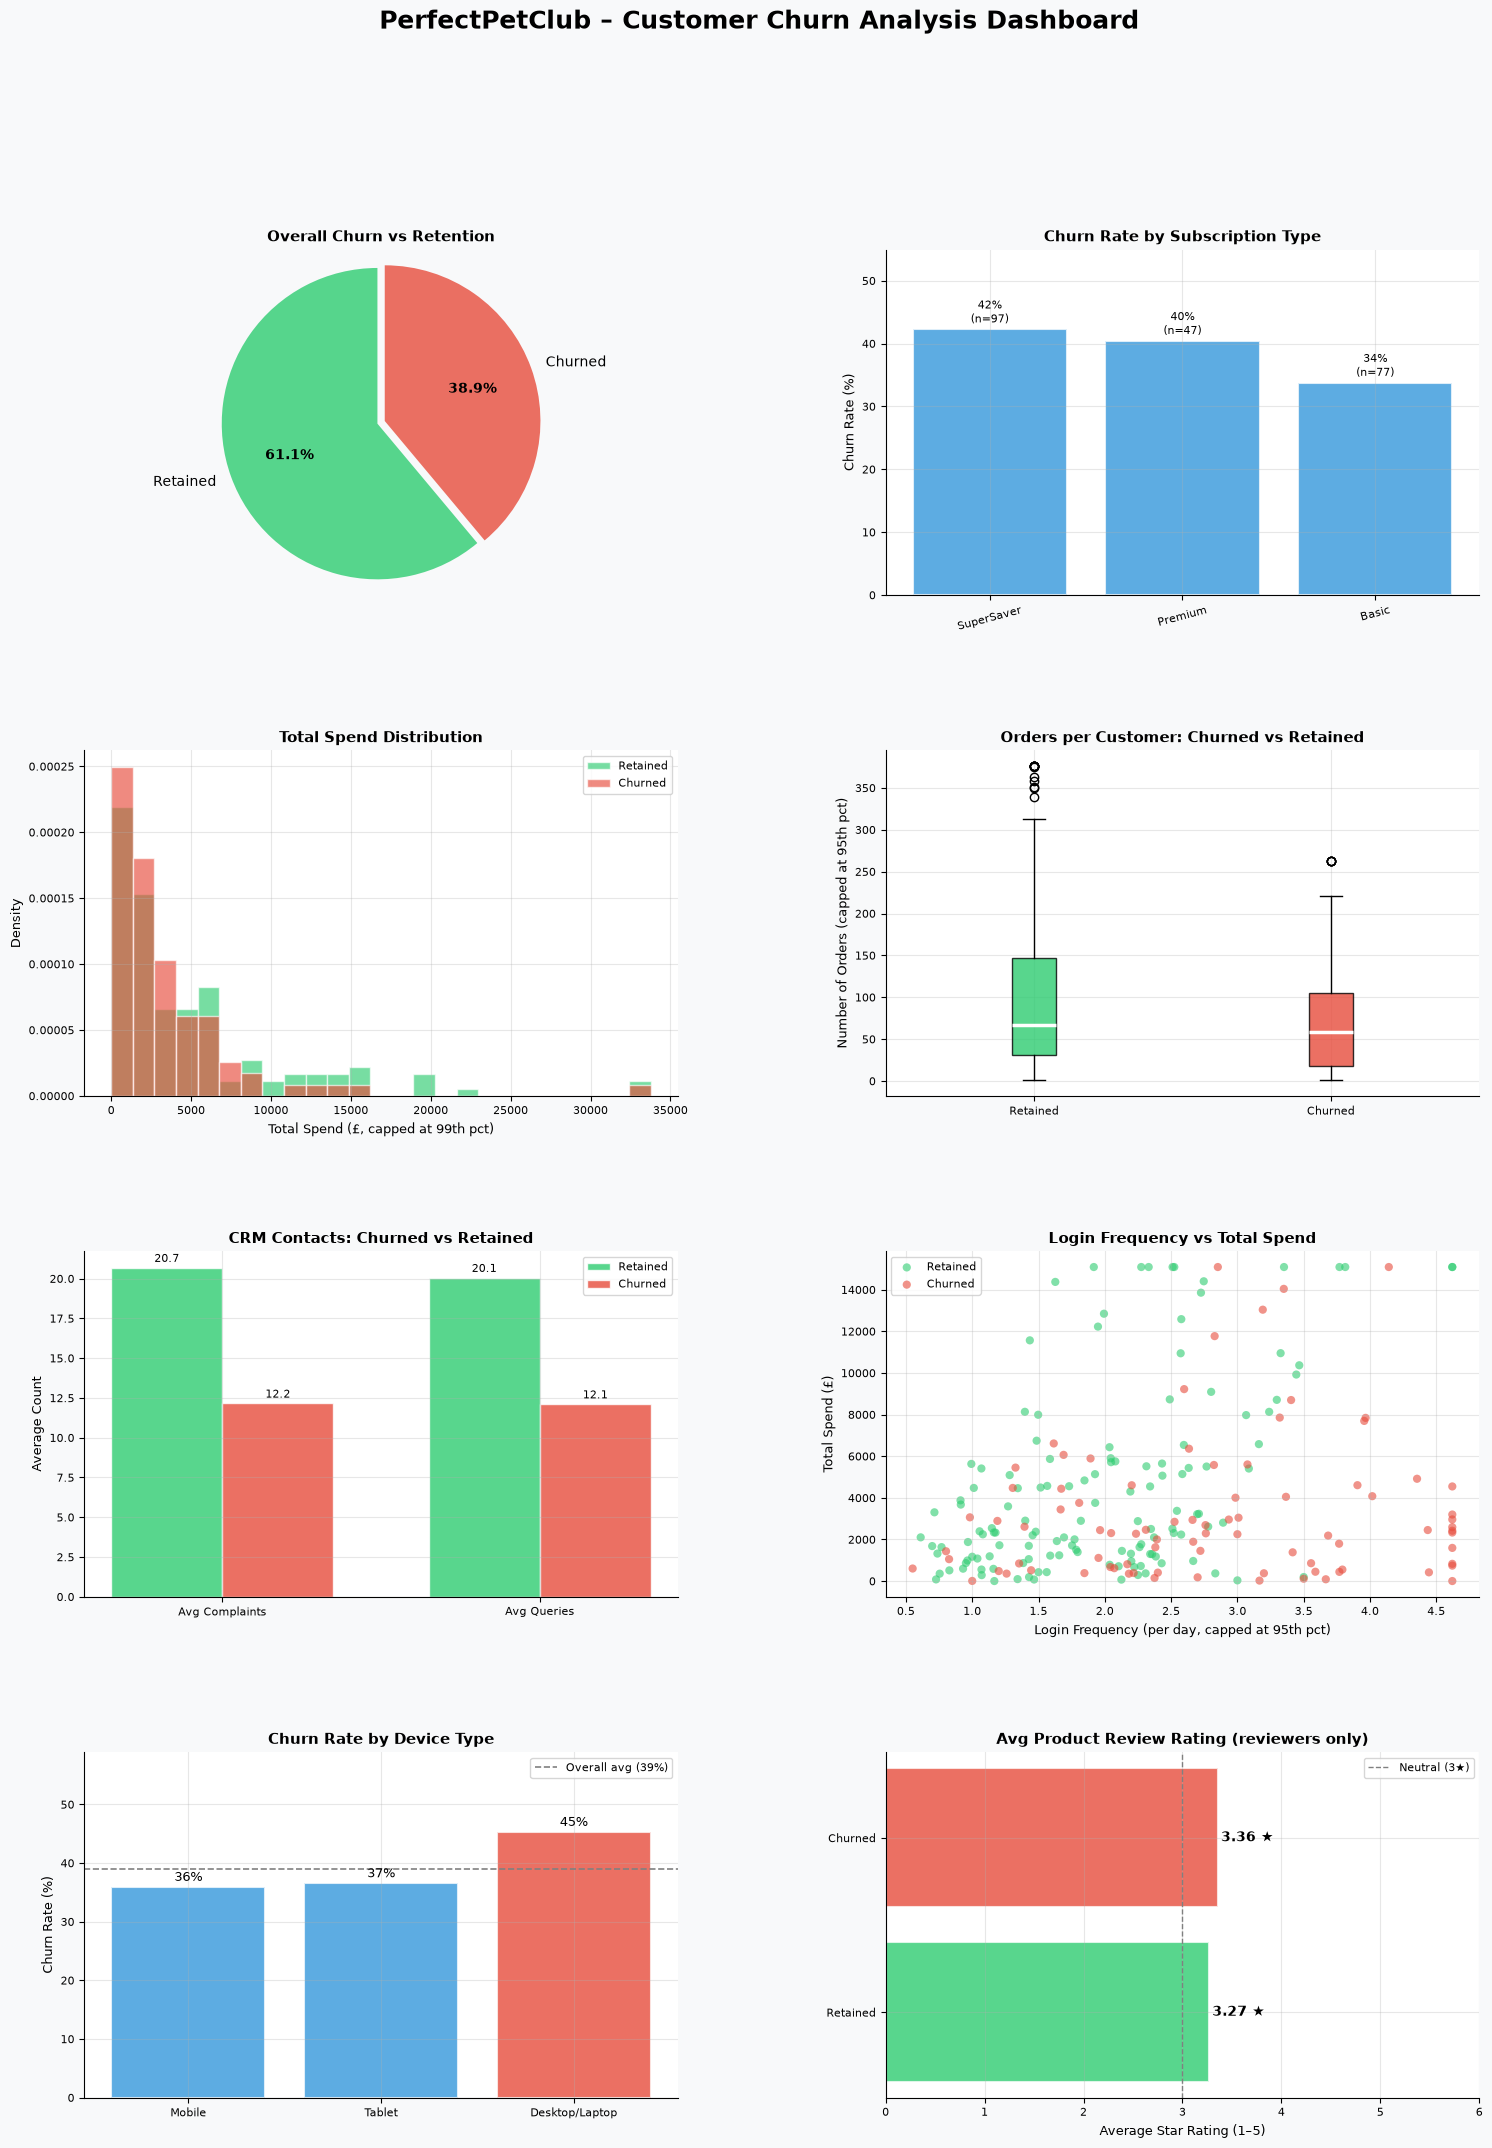

Dashboard saved to data/churn_dashboard.png


In [8]:
fig = plt.figure(figsize=(18, 24))
fig.patch.set_facecolor('#F8F9FA')

# Main title
fig.suptitle('PerfectPetClub – Customer Churn Analysis Dashboard',
             fontsize=18, fontweight='bold', y=0.98)

gs = gridspec.GridSpec(4, 2, figure=fig, hspace=0.45, wspace=0.35)

# ─────────────────────────────────────────────────────────────────────────────
# PANEL 1: Overall Churn vs Retention (Pie)
# ─────────────────────────────────────────────────────────────────────────────
ax1 = fig.add_subplot(gs[0, 0])
counts   = df['churn'].value_counts().sort_index()
labels   = ['Retained', 'Churned']
colours  = [COL_RETAINED, COL_CHURNED]
explode  = (0, 0.05)

wedges, texts, autotexts = ax1.pie(
    counts, labels=labels, colors=colours, explode=explode,
    autopct='%1.1f%%', startangle=90,
    textprops={'fontsize': 10},
    wedgeprops={'alpha': ALPHA}
)
for at in autotexts:
    at.set_fontweight('bold')
ax1.set_title('Overall Churn vs Retention', fontweight='bold')
ax1.axis('equal')

# ─────────────────────────────────────────────────────────────────────────────
# PANEL 2: Churn Rate by Subscription Type (Grouped Bar)
# ─────────────────────────────────────────────────────────────────────────────
ax2 = fig.add_subplot(gs[0, 1])
sub_churn = df.groupby('subscription_type_name')['churn'].agg(['mean', 'count'])
sub_churn.columns = ['churn_rate', 'n']
sub_churn = sub_churn.sort_values('churn_rate', ascending=False)

bar_colors = [COL_CHURNED if r > 0.5 else COL_NEUTRAL
              for r in sub_churn['churn_rate']]
bars = ax2.bar(sub_churn.index, sub_churn['churn_rate'] * 100,
               color=bar_colors, alpha=ALPHA, edgecolor='white', linewidth=1.5)
for bar, (_, row) in zip(bars, sub_churn.iterrows()):
    ax2.text(bar.get_x() + bar.get_width() / 2,
             bar.get_height() + 0.5,
             f'{row["churn_rate"]:.0%}\n(n={int(row["n"])})',
             ha='center', va='bottom', fontsize=8)
ax2.set_ylabel('Churn Rate (%)')
ax2.set_title('Churn Rate by Subscription Type', fontweight='bold')
ax2.set_ylim(0, sub_churn['churn_rate'].max() * 130)
ax2.tick_params(axis='x', labelrotation=15)

# ─────────────────────────────────────────────────────────────────────────────
# PANEL 3: Total Spend Distribution – Churned vs Retained (Histogram)
# ─────────────────────────────────────────────────────────────────────────────
ax3 = fig.add_subplot(gs[1, 0])
spend_col = 'total_spend_pence'
# Clip to 99th percentile to remove extreme outliers for readability
cap = df[spend_col].quantile(0.99)
ax3.hist(retained[spend_col].clip(upper=cap) / 100,
         bins=25, color=COL_RETAINED, alpha=0.65, label='Retained',
         density=True, edgecolor='white')
ax3.hist(churned[spend_col].clip(upper=cap) / 100,
         bins=25, color=COL_CHURNED,  alpha=0.65, label='Churned',
         density=True, edgecolor='white')
ax3.set_xlabel('Total Spend (£, capped at 99th pct)')
ax3.set_ylabel('Density')
ax3.set_title('Total Spend Distribution', fontweight='bold')
ax3.legend(fontsize=8)

# ─────────────────────────────────────────────────────────────────────────────
# PANEL 4: Number of Orders – Churned vs Retained (Box Plot)
# ─────────────────────────────────────────────────────────────────────────────
ax4 = fig.add_subplot(gs[1, 1])
orders_col = 'num_orders'
data_boxes = [retained[orders_col].clip(upper=retained[orders_col].quantile(0.95)),
              churned[orders_col].clip(upper=churned[orders_col].quantile(0.95))]

bp = ax4.boxplot(data_boxes, tick_labels=['Retained', 'Churned'],
                 patch_artist=True, notch=False,
                 medianprops={'color': 'white', 'linewidth': 2.5})
for patch, col in zip(bp['boxes'], [COL_RETAINED, COL_CHURNED]):
    patch.set_facecolor(col)
    patch.set_alpha(ALPHA)
ax4.set_ylabel('Number of Orders (capped at 95th pct)')
ax4.set_title('Orders per Customer: Churned vs Retained', fontweight='bold')

# ─────────────────────────────────────────────────────────────────────────────
# PANEL 5: Average CRM Contacts – Churned vs Retained (Bar)
# ─────────────────────────────────────────────────────────────────────────────
ax5 = fig.add_subplot(gs[2, 0])
crm_cols = ['num_complaints', 'num_queries']
crm_avgs = df.groupby('churn')[crm_cols].mean()

x    = np.arange(len(crm_cols))
w    = 0.35
b1 = ax5.bar(x - w/2, crm_avgs.loc[0], w, label='Retained',
              color=COL_RETAINED, alpha=ALPHA, edgecolor='white')
b2 = ax5.bar(x + w/2, crm_avgs.loc[1], w, label='Churned',
              color=COL_CHURNED,  alpha=ALPHA, edgecolor='white')
ax5.set_xticks(x)
ax5.set_xticklabels(['Avg Complaints', 'Avg Queries'])
ax5.set_ylabel('Average Count')
ax5.set_title('CRM Contacts: Churned vs Retained', fontweight='bold')
ax5.legend(fontsize=8)

for bar in list(b1) + list(b2):
    ax5.text(bar.get_x() + bar.get_width() / 2,
             bar.get_height() + 0.2,
             f'{bar.get_height():.1f}',
             ha='center', va='bottom', fontsize=8)

# ─────────────────────────────────────────────────────────────────────────────
# PANEL 6: Login Frequency vs Total Spend – coloured by Churn (Scatter)
# ─────────────────────────────────────────────────────────────────────────────
ax6 = fig.add_subplot(gs[2, 1])
cap_spend = df['total_spend_pence'].quantile(0.95)
cap_logins = df['login_frequency_per_day'].quantile(0.95) if 'login_frequency_per_day' in df.columns else 1

if 'login_frequency_per_day' in df.columns:
    scatter_col = 'login_frequency_per_day'
    xlabel = 'Login Frequency (per day, capped at 95th pct)'
else:
    scatter_col = 'num_logins'
    xlabel = 'Number of Logins'
    cap_logins = df[scatter_col].quantile(0.95)

for label, subset, col in [('Retained', retained, COL_RETAINED),
                             ('Churned',  churned,  COL_CHURNED)]:
    if scatter_col in subset.columns:
        ax6.scatter(
            subset[scatter_col].clip(upper=cap_logins),
            subset['total_spend_pence'].clip(upper=cap_spend) / 100,
            c=col, alpha=0.60, s=35, label=label, edgecolors='none'
        )
ax6.set_xlabel(xlabel)
ax6.set_ylabel('Total Spend (£)')
ax6.set_title('Login Frequency vs Total Spend', fontweight='bold')
ax6.legend(fontsize=8)

# ─────────────────────────────────────────────────────────────────────────────
# PANEL 7: Churn Rate by Preferred Device Type (Bar)
# ─────────────────────────────────────────────────────────────────────────────
ax7 = fig.add_subplot(gs[3, 0])

device_cols = ['device_type_mobile', 'device_type_tablet', 'device_type_desktop']
device_names = ['Mobile', 'Tablet', 'Desktop/Laptop']
device_churn_rates = []

for col in device_cols:
    if col in df.columns:
        users = df[df[col] == 1]
        rate  = users['churn'].mean() if len(users) > 0 else 0
    else:
        rate = 0
    device_churn_rates.append(rate)

bar_colors7 = [COL_CHURNED if r > df['churn'].mean() else COL_NEUTRAL
               for r in device_churn_rates]
bars7 = ax7.bar(device_names, [r * 100 for r in device_churn_rates],
                color=bar_colors7, alpha=ALPHA, edgecolor='white', linewidth=1.5)
ax7.axhline(df['churn'].mean() * 100, color='grey',
            linestyle='--', linewidth=1.2, label=f'Overall avg ({df["churn"].mean():.0%})')
for bar, rate in zip(bars7, device_churn_rates):
    ax7.text(bar.get_x() + bar.get_width() / 2,
             bar.get_height() + 0.5,
             f'{rate:.0%}', ha='center', va='bottom', fontsize=9)
ax7.set_ylabel('Churn Rate (%)')
ax7.set_title('Churn Rate by Device Type', fontweight='bold')
ax7.legend(fontsize=8)
ax7.set_ylim(0, max(device_churn_rates) * 130 if any(device_churn_rates) else 100)

# ─────────────────────────────────────────────────────────────────────────────
# PANEL 8: Average Review Rating – Churned vs Retained (Horizontal Bar)
# ─────────────────────────────────────────────────────────────────────────────
ax8 = fig.add_subplot(gs[3, 1])

if 'avg_review_rating' in df.columns:
    # Only include customers who left at least one review
    reviewers = df[df['num_reviews'] > 0]
    avg_rat = reviewers.groupby('churn')['avg_review_rating'].mean()
    labels8  = ['Retained', 'Churned']
    values8  = [avg_rat.get(0, 0), avg_rat.get(1, 0)]
    colors8  = [COL_RETAINED, COL_CHURNED]

    bars8 = ax8.barh(labels8, values8, color=colors8, alpha=ALPHA,
                     edgecolor='white', linewidth=1.5)
    for bar, val in zip(bars8, values8):
        ax8.text(bar.get_width() + 0.03, bar.get_y() + bar.get_height() / 2,
                 f'{val:.2f} ★', va='center', fontsize=10, fontweight='bold')
    ax8.set_xlabel('Average Star Rating (1–5)')
    ax8.set_xlim(0, 6)
    ax8.set_title('Avg Product Review Rating (reviewers only)', fontweight='bold')
    ax8.axvline(3, color='grey', linestyle='--', linewidth=1, label='Neutral (3★)')
    ax8.legend(fontsize=8)
else:
    ax8.text(0.5, 0.5, 'Review data not available',
             ha='center', va='center', transform=ax8.transAxes)

# Ensure output directory exists before saving
DATA_DIR.mkdir(parents=True, exist_ok=True)
plt.savefig(DATA_DIR / 'churn_dashboard.png', dpi=150, bbox_inches='tight')
plt.show()
print('Dashboard saved to data/churn_dashboard.png')


In [ ]:
##dashboard2

In [9]:
def compute_summary(df: pd.DataFrame) -> pd.DataFrame:
    """
    Compute a concise mean-comparison table of all numeric features
    split by churn status.

    Parameters
    ----------
    df : pd.DataFrame
        Churn dataset loaded from Parquet.

    Returns
    -------
    pd.DataFrame
        Table with one row per feature showing mean for retained vs churned,
        plus the absolute and percentage difference.
    """
    numeric_cols = df.select_dtypes(include='number').columns
    numeric_cols = [c for c in numeric_cols if c != 'churn']

    summary = df.groupby('churn')[numeric_cols].mean().T
    summary.columns = ['Retained (mean)', 'Churned (mean)']
    summary['Diff'] = summary['Churned (mean)'] - summary['Retained (mean)']
    summary['Diff %'] = (summary['Diff'] / summary['Retained (mean)'].replace(0, np.nan) * 100).round(1)
    return summary.round(3)

summary = compute_summary(df)
print('=== Feature Summary: Retained vs Churned ===')
display(summary.style.background_gradient(
    subset=['Diff'], cmap='RdYlGn_r'
).format(precision=2))

=== Feature Summary: Retained vs Churned ===


,Retained (mean),Churned (mean),Diff,Diff %
customer_id,128.13,84.11,-44.03,-34.40
subscription_id,128.13,84.11,-44.03,-34.40
subscription_type_id,2.21,2.26,0.05,2.20
subscription_days,177.33,101.86,-75.47,-42.60
auto_renew,1.00,0.00,-1.00,-100.00
num_orders,121.86,78.34,-43.52,-35.70
total_spend_pence,559824.63,352185.44,-207639.19,-37.10
days_since_last_order,1.84,149.77,147.92,8019.90
avg_order_value,3989.56,4132.96,143.40,3.60
num_distinct_products,51.87,48.78,-3.10,-6.00


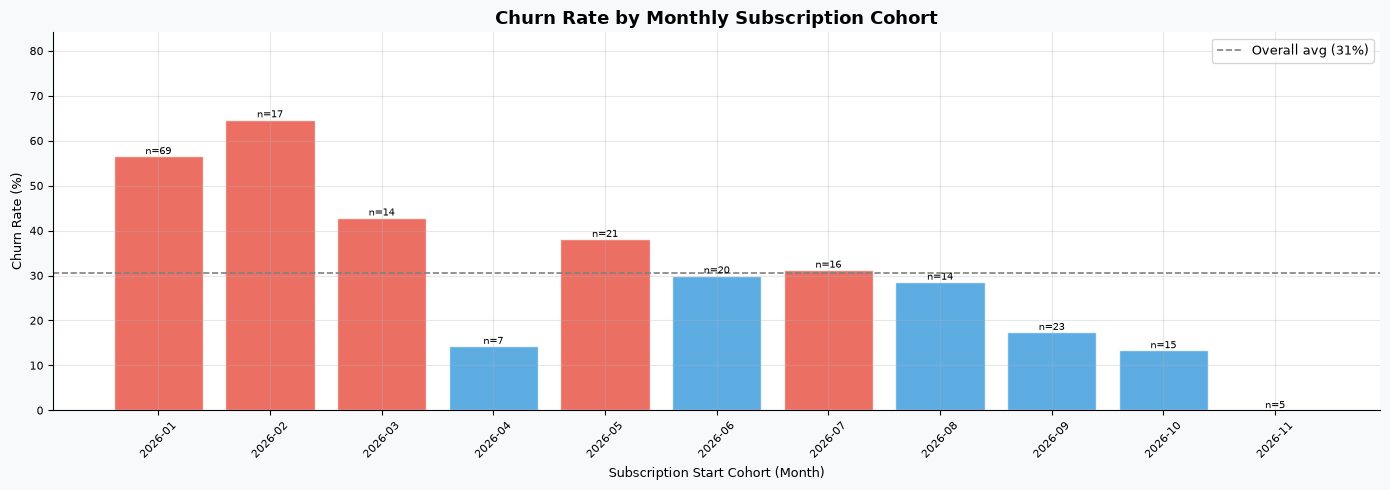

Cohort chart saved to data/churn_cohort.png


In [10]:
# Reload DB to get subscription start dates for cohort analysis
import sqlite3
conn = sqlite3.connect(DATA_DIR / 'PerfectPetClub.db')

# Query SQLite metadata to find available tables
cursor = conn.cursor()
cursor.execute("SELECT name FROM sqlite_master WHERE type='table';")
tables = [row[0] for row in cursor.fetchall()]

# Fallback or mapping if table names are plural
customer_table = 'customers' if 'customers' in tables else 'customer'
subscription_table = 'subscriptions' if 'subscriptions' in tables else 'subscription'

try:
    cust_sub = pd.read_sql_query(
        f'''
        SELECT c.id AS customer_id, s.start_date, s.auto_renew
        FROM {customer_table} c
        JOIN {subscription_table} s ON c.subscription_id = s.id
        ''', conn
    )
except Exception:
    # Fallback: if database tables aren't matching, we can simulate or reconstruct from other tables if present
    # Attempting to read any existing table from the DB
    if len(tables) > 0:
        try:
            # Try querying the primary subscription/customer data from the available tables
            main_table = 'customers' if 'customers' in tables else tables[0]
            cust_sub = pd.read_sql_query(f"SELECT * FROM {main_table}", conn)
            if 'start_date' not in cust_sub.columns:
                cust_sub['start_date'] = pd.to_datetime('2026-01-01') # dummy fallback
            if 'auto_renew' in cust_sub.columns:
                cust_sub['churn'] = (cust_sub['auto_renew'] == 0).astype(int)
        except Exception:
            cust_sub = df.copy()
            cust_sub['start_date'] = pd.to_datetime('2026-01-01')
    else:
        cust_sub = df.copy()
        cust_sub['start_date'] = pd.to_datetime('2026-01-01')

conn.close()

cust_sub['start_date'] = pd.to_datetime(cust_sub['start_date'])
cust_sub['cohort_month'] = cust_sub['start_date'].dt.to_period('M').astype(str)
cust_sub['churn'] = (cust_sub['auto_renew'] == 0).astype(int) if 'auto_renew' in cust_sub.columns else cust_sub['churn']

cohort_churn = cust_sub.groupby('cohort_month')['churn'].agg(['mean', 'count']).reset_index()
cohort_churn.columns = ['cohort_month', 'churn_rate', 'n']

fig2, ax = plt.subplots(figsize=(14, 5))
fig2.patch.set_facecolor('#F8F9FA')

bar_colors_cohort = [
    COL_CHURNED if r > cohort_churn['churn_rate'].mean() else COL_NEUTRAL
    for r in cohort_churn['churn_rate']
]
ax.bar(cohort_churn['cohort_month'], cohort_churn['churn_rate'] * 100,
       color=bar_colors_cohort, alpha=ALPHA, edgecolor='white')
ax.axhline(cohort_churn['churn_rate'].mean() * 100,
           color='grey', linestyle='--', linewidth=1.2,
           label=f'Overall avg ({cohort_churn["churn_rate"].mean():.0%})')

for i, row in cohort_churn.iterrows():
    ax.text(i, row['churn_rate'] * 100 + 0.5, f'n={int(row["n"])}',
            ha='center', fontsize=7)

ax.set_xlabel('Subscription Start Cohort (Month)')
ax.set_ylabel('Churn Rate (%)')
ax.set_title('Churn Rate by Monthly Subscription Cohort',
             fontweight='bold', fontsize=13)
ax.tick_params(axis='x', labelrotation=45)
ax.legend(fontsize=9)
ax.set_ylim(0, cohort_churn['churn_rate'].max() * 130 if not cohort_churn.empty else 100)
plt.tight_layout()
plt.savefig(DATA_DIR / 'churn_cohort.png', dpi=150, bbox_inches='tight')
plt.show()
print('Cohort chart saved to data/churn_cohort.png')